In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)

DATA_PATH = Path("../data/processed/model_data.parquet")

model_data = pd.read_parquet(DATA_PATH)

print("Shape:", model_data.shape)
model_data.head()

Shape: (200039, 50)


,client_id,treatment_flg,target,transactions_E1,transactions_E2,transactions_E3,transactions_E4,total_spend_E1,total_spend_E2,total_spend_E3,total_spend_E4,avg_basket_spend_E1,avg_basket_spend_E2,avg_basket_spend_E3,avg_basket_spend_E4,total_quantity_E1,total_quantity_E2,total_quantity_E3,total_quantity_E4,avg_quantity_E1,avg_quantity_E2,avg_quantity_E3,avg_quantity_E4,avg_unique_products_E1,avg_unique_products_E2,avg_unique_products_E3,avg_unique_products_E4,transactions_trend,total_spend_trend,avg_basket_spend_trend,total_quantity_trend,transactions_historical_mean,transactions_recent_deviation,total_spend_historical_mean,total_spend_recent_deviation,avg_basket_spend_historical_mean,avg_basket_spend_recent_deviation,total_quantity_historical_mean,total_quantity_recent_deviation,transactions_recent_deviation_z,total_spend_recent_deviation_z,avg_basket_spend_recent_deviation_z,total_quantity_recent_deviation_z,behavioral_instability,category_drift_E1_E3,category_drift_E3_E4,category_drift_history_E4,history_periods_active,historical_category_lines,instability_quartile
0,000012768d,0,1,2.0,0.0,0.0,2.0,1581.00,0.00,0.00,1222.00,790.500,0.00,0.00,611.000000,35.0,0.0,0.0,19.0,17.5,0.00,0.000000,9.500000,15.0,0.0,0.00,11.000000,-1.0,-790.500,-395.2500,-17.5,0.666667,1.333333,527.000000,695.000000,263.500000,347.500000,11.666667,7.333333,0.032398,0.071246,0.717560,-0.052745,0.218487,NaN,NaN,0.402096,1,30.0,Q1 Stable
1,000036f903,1,1,10.0,4.0,10.0,8.0,2947.00,1492.00,2582.00,2784.00,294.700,373.00,258.20,348.000000,47.0,27.0,45.0,50.0,4.7,6.75,4.500000,6.250000,4.8,6.0,4.60,5.500000,0.0,-182.500,-18.2500,-1.0,8.000000,0.000000,2340.333333,443.666667,308.633333,39.366667,39.666667,10.333333,-0.315213,-0.049806,-0.121292,0.038372,0.131171,0.297634,0.310009,0.305435,3,118.0,Q1 Stable
2,00010925a5,1,1,5.0,1.0,4.0,7.0,1394.00,438.00,1395.00,2353.00,278.800,438.00,348.75,336.142857,23.0,4.0,18.0,27.0,4.6,4.00,4.500000,3.857143,4.6,5.0,4.25,4.000000,-0.5,0.500,34.9750,-2.5,3.333333,3.666667,1075.666667,1277.333333,355.183333,-19.040476,15.000000,12.000000,0.640719,0.351722,-0.280297,0.088992,0.340433,0.272464,0.499278,0.512642,3,45.0,Q2
3,0001f552b0,1,1,2.0,2.0,4.0,6.0,922.31,1332.42,908.68,2071.88,461.155,666.21,227.17,345.313333,15.0,31.0,25.0,24.0,7.5,15.50,6.250000,4.000000,6.5,9.0,4.25,4.666667,1.0,-6.815,-116.9925,5.0,2.666667,3.333333,1054.470000,1017.410000,451.511667,-106.198333,23.666667,0.333333,0.553816,0.226532,-0.517573,-0.265351,0.390818,0.449412,0.593368,0.578300,3,48.0,Q2
4,00020e7b18,1,1,5.0,1.0,6.0,5.0,5994.28,4205.61,6979.38,6096.27,1198.856,4205.61,1163.23,1219.254000,101.0,58.0,100.0,89.0,20.2,58.00,16.666667,17.800000,13.6,41.0,12.50,12.000000,0.5,492.550,-17.8130,-0.5,4.000000,1.000000,5726.423333,369.846667,2189.232000,-969.978000,86.333333,2.666667,-0.054504,-0.085361,-2.869098,-0.194482,0.800861,0.315146,0.185073,0.170853,3,184.0,Q4 High Change


In [3]:
print("Columns:")
for col in model_data.columns:
    print(col)

print("\nMissing values:")
display(
    model_data.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing")
    .head(20)
)

print("\nTreatment / outcome:")
display(
    pd.crosstab(
        model_data["treatment_flg"],
        model_data["target"],
        margins=True
    )
)

Columns:
client_id
treatment_flg
target
transactions_E1
transactions_E2
transactions_E3
transactions_E4
total_spend_E1
total_spend_E2
total_spend_E3
total_spend_E4
avg_basket_spend_E1
avg_basket_spend_E2
avg_basket_spend_E3
avg_basket_spend_E4
total_quantity_E1
total_quantity_E2
total_quantity_E3
total_quantity_E4
avg_quantity_E1
avg_quantity_E2
avg_quantity_E3
avg_quantity_E4
avg_unique_products_E1
avg_unique_products_E2
avg_unique_products_E3
avg_unique_products_E4
transactions_trend
total_spend_trend
avg_basket_spend_trend
total_quantity_trend
transactions_historical_mean
transactions_recent_deviation
total_spend_historical_mean
total_spend_recent_deviation
avg_basket_spend_historical_mean
avg_basket_spend_recent_deviation
total_quantity_historical_mean
total_quantity_recent_deviation
transactions_recent_deviation_z
total_spend_recent_deviation_z
avg_basket_spend_recent_deviation_z
total_quantity_recent_deviation_z
behavioral_instability
category_drift_E1_E3
category_drift_E3_E4
cat

,missing
category_drift_E1_E3,55560
category_drift_E3_E4,27771
category_drift_history_E4,10413
client_id,0
avg_basket_spend_recent_deviation,0
transactions_trend,0
total_spend_trend,0
avg_basket_spend_trend,0
total_quantity_trend,0
transactions_historical_mean,0



Treatment / outcome:


target,0,1,All
treatment_flg,,,
0,39695,60363,100058
1,36342,63639,99981
All,76037,124002,200039


In [4]:
behavior_metrics = [
    "transactions",
    "total_spend",
    "avg_basket_spend",
    "total_quantity",
    "avg_quantity",
    "avg_unique_products"
]

for feature in behavior_metrics:
    period_cols = [
        f"{feature}_E1",
        f"{feature}_E2",
        f"{feature}_E3",
        f"{feature}_E4"
    ]

    model_data[f"{feature}_static_mean"] = (
        model_data[period_cols].mean(axis=1)
    )

In [5]:
static_features = [
    "transactions_static_mean",
    "total_spend_static_mean",
    "avg_basket_spend_static_mean",
    "total_quantity_static_mean",
    "avg_quantity_static_mean",
    "avg_unique_products_static_mean",
    "historical_category_lines",
    "history_periods_active"
]

print("Static features:", len(static_features))
print(static_features)

Static features: 8
['transactions_static_mean', 'total_spend_static_mean', 'avg_basket_spend_static_mean', 'total_quantity_static_mean', 'avg_quantity_static_mean', 'avg_unique_products_static_mean', 'historical_category_lines', 'history_periods_active']


In [6]:
adaptive_features = []

for feature in behavior_metrics:
    adaptive_features.extend([
        f"{feature}_E1",
        f"{feature}_E2",
        f"{feature}_E3",
        f"{feature}_E4"
    ])

adaptive_features += [
    "transactions_trend",
    "total_spend_trend",
    "avg_basket_spend_trend",
    "total_quantity_trend",

    "transactions_recent_deviation",
    "total_spend_recent_deviation",
    "avg_basket_spend_recent_deviation",
    "total_quantity_recent_deviation",

    "behavioral_instability",

    "category_drift_E1_E3",
    "category_drift_E3_E4",
    "category_drift_history_E4",

    "historical_category_lines",
    "history_periods_active"
]

print("Adaptive features:", len(adaptive_features))

Adaptive features: 38


In [7]:
drift_features = [
    "category_drift_E1_E3",
    "category_drift_E3_E4",
    "category_drift_history_E4"
]

for feature in drift_features:
    indicator = f"{feature}_missing"

    model_data[indicator] = (
        model_data[feature].isna().astype(int)
    )

    model_data[feature] = (
        model_data[feature].fillna(0)
    )

    adaptive_features.append(indicator)

In [8]:
print("Static:", len(static_features))
print("Adaptive:", len(adaptive_features))

print(
    "\nStatic missing:",
    model_data[static_features].isna().sum().sum()
)

print(
    "Adaptive missing:",
    model_data[adaptive_features].isna().sum().sum()
)

Static: 8
Adaptive: 41

Static missing: 0
Adaptive missing: 0


In [9]:
from sklearn.model_selection import train_test_split

model_data["stratify_group"] = (
    model_data["treatment_flg"].astype(str)
    + "_"
    + model_data["target"].astype(str)
)

train_data, temp_data = train_test_split(
    model_data,
    test_size=0.40,
    random_state=42,
    stratify=model_data["stratify_group"]
)

val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=42,
    stratify=temp_data["stratify_group"]
)

print("Train:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_data.shape)

Train: (120023, 60)
Validation: (40008, 60)
Test: (40008, 60)


In [10]:
for name, df in [
    ("Train", train_data),
    ("Validation", val_data),
    ("Test", test_data)
]:
    print(f"\n{name}")
    
    print(
        pd.crosstab(
            df["treatment_flg"],
            df["target"],
            normalize="all"
        ).round(4)
    )


Train
target              0       1
treatment_flg                
0              0.1984  0.3018
1              0.1817  0.3181

Validation
target              0       1
treatment_flg                
0              0.1984  0.3017
1              0.1817  0.3181

Test
target              0       1
treatment_flg                
0              0.1984  0.3018
1              0.1817  0.3181


In [11]:
for name, df in [
    ("Train", train_data),
    ("Validation", val_data),
    ("Test", test_data)
]:
    control_rate = df.loc[
        df["treatment_flg"] == 0,
        "target"
    ].mean()

    treated_rate = df.loc[
        df["treatment_flg"] == 1,
        "target"
    ].mean()

    print(
        f"{name:10s} | "
        f"Control: {control_rate:.4f} | "
        f"Treated: {treated_rate:.4f} | "
        f"ATE: {treated_rate - control_rate:.4f}"
    )

Train      | Control: 0.6033 | Treated: 0.6365 | ATE: 0.0332
Validation | Control: 0.6033 | Treated: 0.6365 | ATE: 0.0332
Test       | Control: 0.6033 | Treated: 0.6365 | ATE: 0.0332


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

response_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

response_model.fit(
    train_data[static_features],
    train_data["target"]
)

val_response_pred = response_model.predict_proba(
    val_data[static_features]
)[:, 1]

print(
    "Validation ROC-AUC:",
    round(
        roc_auc_score(
            val_data["target"],
            val_response_pred
        ),
        4
    )
)

print(
    "Validation Log Loss:",
    round(
        log_loss(
            val_data["target"],
            val_response_pred
        ),
        4
    )
)

Validation ROC-AUC: 0.7588
Validation Log Loss: 0.5664


In [13]:
val_eval = val_data[
    ["client_id", "treatment_flg", "target"]
].copy()

val_eval["response_score"] = val_response_pred

cutoff = val_eval["response_score"].quantile(0.80)

val_eval["response_targeted"] = (
    val_eval["response_score"] >= cutoff
).astype(int)

print(
    "Targeted:",
    val_eval["response_targeted"].mean()
)

Targeted: 0.20000999800039992


In [14]:
targeted = val_eval[
    val_eval["response_targeted"] == 1
]

treated_rate = targeted.loc[
    targeted["treatment_flg"] == 1,
    "target"
].mean()

control_rate = targeted.loc[
    targeted["treatment_flg"] == 0,
    "target"
].mean()

targeted_ate = treated_rate - control_rate

print("Targeted customers:", len(targeted))
print("Control purchase rate:", round(control_rate, 4))
print("Treated purchase rate:", round(treated_rate, 4))
print("Targeted ATE:", round(targeted_ate, 4))

Targeted customers: 8002
Control purchase rate: 0.8932
Treated purchase rate: 0.9043
Targeted ATE: 0.0111


In [15]:
print(
    "Incremental purchases per 10,000 messages:",
    round(targeted_ate * 10000)
)

Incremental purchases per 10,000 messages: 111


In [16]:
static_s_features = static_features + ["treatment_flg"]

static_s_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

static_s_model.fit(
    train_data[static_s_features],
    train_data["target"]
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [17]:
val_treated = val_data[static_s_features].copy()
val_control = val_data[static_s_features].copy()

val_treated["treatment_flg"] = 1
val_control["treatment_flg"] = 0

In [18]:
pred_treated = static_s_model.predict_proba(
    val_treated
)[:, 1]

pred_control = static_s_model.predict_proba(
    val_control
)[:, 1]

static_uplift = pred_treated - pred_control

In [19]:
pd.Series(static_uplift).describe(
    percentiles=[.01, .05, .10, .25, .50, .75, .90, .95, .99]
)

count    4.000800e+04
mean     3.178040e-02
std      1.123603e-02
min      2.220446e-16
1%       5.277951e-04
5%       5.465843e-03
10%      1.223150e-02
25%      2.716531e-02
50%      3.693498e-02
75%      4.000292e-02
90%      4.071672e-02
95%      4.081219e-02
99%      4.084411e-02
max      4.084565e-02
dtype: float64

In [20]:
static_eval = val_data[
    ["client_id", "treatment_flg", "target"]
].copy()

static_eval["predicted_uplift"] = static_uplift

cutoff = static_eval[
    "predicted_uplift"
].quantile(0.80)

static_eval["targeted"] = (
    static_eval["predicted_uplift"] >= cutoff
).astype(int)

static_targeted = static_eval[
    static_eval["targeted"] == 1
]

treated_rate = static_targeted.loc[
    static_targeted["treatment_flg"] == 1,
    "target"
].mean()

control_rate = static_targeted.loc[
    static_targeted["treatment_flg"] == 0,
    "target"
].mean()

static_targeted_ate = treated_rate - control_rate

print("Targeted customers:", len(static_targeted))
print("Control purchase rate:", round(control_rate, 4))
print("Treated purchase rate:", round(treated_rate, 4))
print("Targeted ATE:", round(static_targeted_ate, 4))

print(
    "Incremental purchases per 10,000 messages:",
    round(static_targeted_ate * 10000)
)

Targeted customers: 8002
Control purchase rate: 0.4905
Treated purchase rate: 0.5373
Targeted ATE: 0.0469
Incremental purchases per 10,000 messages: 469


In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier

static_gb_s_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=15,
    min_samples_leaf=50,
    l2_regularization=1.0,
    random_state=42
)

static_gb_s_model.fit(
    train_data[static_s_features],
    train_data["target"]
)

HistGradientBoostingClassifier(l2_regularization=1.0, learning_rate=0.05,
                               max_iter=200, max_leaf_nodes=15,
                               min_samples_leaf=50, random_state=42)

In [22]:
val_treated = val_data[static_s_features].copy()
val_control = val_data[static_s_features].copy()

val_treated["treatment_flg"] = 1
val_control["treatment_flg"] = 0

static_gb_treated = static_gb_s_model.predict_proba(
    val_treated
)[:, 1]

static_gb_control = static_gb_s_model.predict_proba(
    val_control
)[:, 1]

static_gb_uplift = (
    static_gb_treated - static_gb_control
)

In [23]:
pd.Series(static_gb_uplift).describe(
    percentiles=[
        .01, .05, .10, .25,
        .50, .75, .90, .95, .99
    ]
)

count    40008.000000
mean         0.027346
std          0.022976
min         -0.084392
1%          -0.009077
5%           0.000390
10%          0.003788
25%          0.010541
50%          0.022155
75%          0.038494
90%          0.060707
95%          0.076361
99%          0.094060
max          0.148828
dtype: float64

In [24]:
gb_eval = val_data[
    ["client_id", "treatment_flg", "target"]
].copy()

gb_eval["predicted_uplift"] = static_gb_uplift

cutoff = gb_eval[
    "predicted_uplift"
].quantile(0.80)

gb_targeted = gb_eval[
    gb_eval["predicted_uplift"] >= cutoff
]

treated_rate = gb_targeted.loc[
    gb_targeted["treatment_flg"] == 1,
    "target"
].mean()

control_rate = gb_targeted.loc[
    gb_targeted["treatment_flg"] == 0,
    "target"
].mean()

gb_ate = treated_rate - control_rate

print("Targeted customers:", len(gb_targeted))
print("Control purchase rate:", round(control_rate, 4))
print("Treated purchase rate:", round(treated_rate, 4))
print("Targeted ATE:", round(gb_ate, 4))

print(
    "Incremental purchases per 10,000 messages:",
    round(gb_ate * 10000)
)

Targeted customers: 8002
Control purchase rate: 0.437
Treated purchase rate: 0.4941
Targeted ATE: 0.0572
Incremental purchases per 10,000 messages: 572


In [25]:
adaptive_s_features = adaptive_features + ["treatment_flg"]

adaptive_gb_s_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=15,
    min_samples_leaf=50,
    l2_regularization=1.0,
    random_state=42
)

adaptive_gb_s_model.fit(
    train_data[adaptive_s_features],
    train_data["target"]
)

HistGradientBoostingClassifier(l2_regularization=1.0, learning_rate=0.05,
                               max_iter=200, max_leaf_nodes=15,
                               min_samples_leaf=50, random_state=42)

In [26]:
val_adaptive_treated = val_data[
    adaptive_s_features
].copy()

val_adaptive_control = val_data[
    adaptive_s_features
].copy()

val_adaptive_treated["treatment_flg"] = 1
val_adaptive_control["treatment_flg"] = 0

adaptive_pred_treated = (
    adaptive_gb_s_model.predict_proba(
        val_adaptive_treated
    )[:, 1]
)

adaptive_pred_control = (
    adaptive_gb_s_model.predict_proba(
        val_adaptive_control
    )[:, 1]
)

adaptive_uplift = (
    adaptive_pred_treated
    - adaptive_pred_control
)

In [27]:
pd.Series(adaptive_uplift).describe(
    percentiles=[
        .01, .05, .10, .25,
        .50, .75, .90, .95, .99
    ]
)

count    40008.000000
mean         0.025335
std          0.018568
min         -0.069442
1%          -0.005668
5%           0.001928
10%          0.004692
25%          0.011399
50%          0.021671
75%          0.036557
90%          0.051809
95%          0.061778
99%          0.075317
max          0.111459
dtype: float64

In [28]:
adaptive_eval = val_data[
    ["client_id", "treatment_flg", "target"]
].copy()

adaptive_eval["predicted_uplift"] = adaptive_uplift

cutoff = adaptive_eval[
    "predicted_uplift"
].quantile(0.80)

adaptive_targeted = adaptive_eval[
    adaptive_eval["predicted_uplift"] >= cutoff
]

treated_rate = adaptive_targeted.loc[
    adaptive_targeted["treatment_flg"] == 1,
    "target"
].mean()

control_rate = adaptive_targeted.loc[
    adaptive_targeted["treatment_flg"] == 0,
    "target"
].mean()

adaptive_ate = treated_rate - control_rate

print("Targeted customers:", len(adaptive_targeted))
print("Control purchase rate:", round(control_rate, 4))
print("Treated purchase rate:", round(treated_rate, 4))
print("Targeted ATE:", round(adaptive_ate, 4))

print(
    "Incremental purchases per 10,000 messages:",
    round(adaptive_ate * 10000)
)

Targeted customers: 8002
Control purchase rate: 0.4095
Treated purchase rate: 0.4609
Targeted ATE: 0.0513
Incremental purchases per 10,000 messages: 513


In [29]:
def evaluate_targeting_policy(
    df,
    uplift_scores,
    budgets=(0.10, 0.20, 0.30, 0.40, 0.50)
):
    results = []

    eval_df = df[
        ["treatment_flg", "target"]
    ].copy()

    eval_df["uplift_score"] = uplift_scores

    for budget in budgets:
        cutoff = eval_df[
            "uplift_score"
        ].quantile(1 - budget)

        selected = eval_df[
            eval_df["uplift_score"] >= cutoff
        ]

        control_rate = selected.loc[
            selected["treatment_flg"] == 0,
            "target"
        ].mean()

        treated_rate = selected.loc[
            selected["treatment_flg"] == 1,
            "target"
        ].mean()

        ate = treated_rate - control_rate

        results.append({
            "budget": budget,
            "n_targeted": len(selected),
            "control_rate": control_rate,
            "treated_rate": treated_rate,
            "ate": ate,
            "incremental_per_10k": ate * 10000
        })

    return pd.DataFrame(results)

In [30]:
static_policy_results = evaluate_targeting_policy(
    val_data,
    static_gb_uplift
)

adaptive_policy_results = evaluate_targeting_policy(
    val_data,
    adaptive_uplift
)

policy_comparison = (
    static_policy_results[
        ["budget", "ate", "incremental_per_10k"]
    ]
    .rename(columns={
        "ate": "static_ate",
        "incremental_per_10k": "static_per_10k"
    })
    .merge(
        adaptive_policy_results[
            ["budget", "ate", "incremental_per_10k"]
        ].rename(columns={
            "ate": "adaptive_ate",
            "incremental_per_10k": "adaptive_per_10k"
        }),
        on="budget"
    )
)

policy_comparison["adaptive_minus_static"] = (
    policy_comparison["adaptive_per_10k"]
    - policy_comparison["static_per_10k"]
)

policy_comparison.round(4)

,budget,static_ate,static_per_10k,adaptive_ate,adaptive_per_10k,adaptive_minus_static
0,0.1,0.0732,732.2538,0.0542,541.7206,-190.5332
1,0.2,0.0572,571.6678,0.0513,513.2991,-58.3687
2,0.3,0.0466,465.7279,0.0594,593.5956,127.8676
3,0.4,0.0448,447.8141,0.0546,546.4247,98.6106
4,0.5,0.0435,434.9130,0.0462,461.6696,26.7565


In [31]:
def uplift_curve(
    df,
    uplift_scores,
    n_bins=20
):
    eval_df = df[
        ["treatment_flg", "target"]
    ].copy()

    eval_df["uplift_score"] = uplift_scores

    eval_df = eval_df.sort_values(
        "uplift_score",
        ascending=False
    ).reset_index(drop=True)

    results = []

    for i in range(1, n_bins + 1):
        n = int(len(eval_df) * i / n_bins)

        selected = eval_df.iloc[:n]

        treated = selected[
            selected["treatment_flg"] == 1
        ]

        control = selected[
            selected["treatment_flg"] == 0
        ]

        treated_rate = treated["target"].mean()
        control_rate = control["target"].mean()

        ate = treated_rate - control_rate

        results.append({
            "fraction_targeted": i / n_bins,
            "n_targeted": n,
            "ate": ate,
            "incremental_per_10k": ate * 10000
        })

    return pd.DataFrame(results)

In [32]:
static_curve = uplift_curve(
    val_data,
    static_gb_uplift
)

adaptive_curve = uplift_curve(
    val_data,
    adaptive_uplift
)

curve_comparison = (
    static_curve[
        ["fraction_targeted", "incremental_per_10k"]
    ]
    .rename(columns={
        "incremental_per_10k": "static_per_10k"
    })
    .merge(
        adaptive_curve[
            ["fraction_targeted", "incremental_per_10k"]
        ].rename(columns={
            "incremental_per_10k": "adaptive_per_10k"
        }),
        on="fraction_targeted"
    )
)

curve_comparison["adaptive_minus_static"] = (
    curve_comparison["adaptive_per_10k"]
    - curve_comparison["static_per_10k"]
)

curve_comparison.round(2)

,fraction_targeted,static_per_10k,adaptive_per_10k,adaptive_minus_static
0,0.05,630.13,767.40,137.27
1,0.10,730.37,543.97,-186.41
2,0.15,590.75,562.13,-28.62
3,0.20,572.90,511.94,-60.96
4,0.25,428.61,597.19,168.58
5,0.30,466.59,592.89,126.30
6,0.35,437.39,598.49,161.09
7,0.40,447.81,546.42,98.61
8,0.45,462.19,507.95,45.76
9,0.50,434.91,461.67,26.76


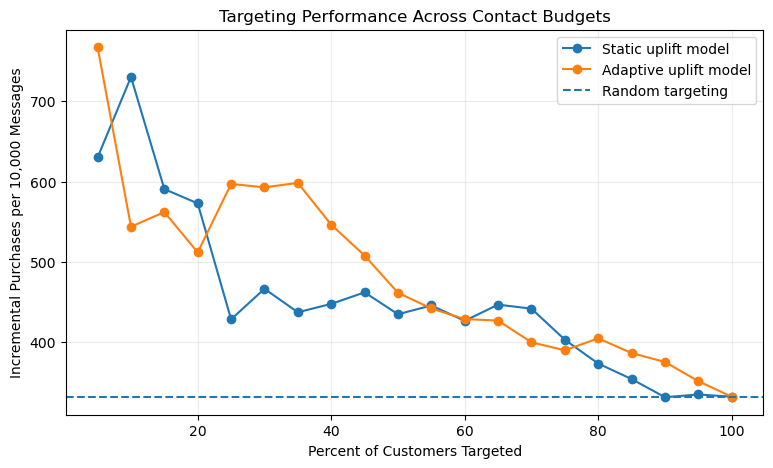

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    curve_comparison["fraction_targeted"] * 100,
    curve_comparison["static_per_10k"],
    marker="o",
    label="Static uplift model"
)

plt.plot(
    curve_comparison["fraction_targeted"] * 100,
    curve_comparison["adaptive_per_10k"],
    marker="o",
    label="Adaptive uplift model"
)

plt.axhline(
    y=332,
    linestyle="--",
    label="Random targeting"
)

plt.xlabel("Percent of Customers Targeted")
plt.ylabel("Incremental Purchases per 10,000 Messages")
plt.title("Targeting Performance Across Contact Budgets")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

In [34]:
instability_eval = val_data[
    [
        "client_id",
        "treatment_flg",
        "target",
        "behavioral_instability"
    ]
].copy()

instability_eval["static_uplift"] = static_gb_uplift
instability_eval["adaptive_uplift"] = adaptive_uplift

instability_eval["instability_group"] = pd.qcut(
    instability_eval["behavioral_instability"],
    q=4,
    labels=[
        "Q1 Stable",
        "Q2",
        "Q3",
        "Q4 High Change"
    ]
)

instability_eval[
    "instability_group"
].value_counts(sort=False)

instability_group
Q1 Stable         10002
Q2                10002
Q3                10002
Q4 High Change    10002
Name: count, dtype: int64

In [35]:
def subgroup_policy_effect(
    df,
    score_col,
    budget=0.20
):
    cutoff = df[score_col].quantile(
        1 - budget
    )

    selected = df[
        df[score_col] >= cutoff
    ]

    control_rate = selected.loc[
        selected["treatment_flg"] == 0,
        "target"
    ].mean()

    treated_rate = selected.loc[
        selected["treatment_flg"] == 1,
        "target"
    ].mean()

    ate = treated_rate - control_rate

    return {
        "n_targeted": len(selected),
        "control_rate": control_rate,
        "treated_rate": treated_rate,
        "ate": ate,
        "incremental_per_10k": ate * 10000
    }

In [36]:
subgroup_results = []

for group, group_df in instability_eval.groupby(
    "instability_group",
    observed=True
):
    static_result = subgroup_policy_effect(
        group_df,
        "static_uplift"
    )

    adaptive_result = subgroup_policy_effect(
        group_df,
        "adaptive_uplift"
    )

    subgroup_results.append({
        "instability_group": group,

        "static_n": static_result["n_targeted"],
        "static_ate": static_result["ate"],
        "static_per_10k":
            static_result["incremental_per_10k"],

        "adaptive_n": adaptive_result["n_targeted"],
        "adaptive_ate": adaptive_result["ate"],
        "adaptive_per_10k":
            adaptive_result["incremental_per_10k"]
    })

subgroup_results = pd.DataFrame(
    subgroup_results
)

subgroup_results["adaptive_minus_static"] = (
    subgroup_results["adaptive_per_10k"]
    - subgroup_results["static_per_10k"]
)

subgroup_results.round(4)

,instability_group,static_n,static_ate,static_per_10k,adaptive_n,adaptive_ate,adaptive_per_10k,adaptive_minus_static
0,Q1 Stable,2001,0.0566,565.7942,2001,0.0442,441.9328,-123.8614
1,Q2,2001,0.0422,422.1742,2001,0.0542,541.8815,119.7074
2,Q3,2001,0.0355,355.0050,2001,0.0636,636.1996,281.1946
3,Q4 High Change,2001,0.0328,327.9740,2001,0.0575,574.5055,246.5315


In [37]:
def bootstrap_policy_difference(
    df,
    budget=0.20,
    n_boot=1000,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    differences = []

    for _ in range(n_boot):
        boot_idx = rng.integers(
            0,
            len(df),
            len(df)
        )

        boot = df.iloc[boot_idx].copy()

        static_cutoff = boot[
            "static_uplift"
        ].quantile(1 - budget)

        adaptive_cutoff = boot[
            "adaptive_uplift"
        ].quantile(1 - budget)

        static_selected = boot[
            boot["static_uplift"] >= static_cutoff
        ]

        adaptive_selected = boot[
            boot["adaptive_uplift"] >= adaptive_cutoff
        ]

        static_treated = static_selected.loc[
            static_selected["treatment_flg"] == 1,
            "target"
        ].mean()

        static_control = static_selected.loc[
            static_selected["treatment_flg"] == 0,
            "target"
        ].mean()

        adaptive_treated = adaptive_selected.loc[
            adaptive_selected["treatment_flg"] == 1,
            "target"
        ].mean()

        adaptive_control = adaptive_selected.loc[
            adaptive_selected["treatment_flg"] == 0,
            "target"
        ].mean()

        static_ate = (
            static_treated - static_control
        )

        adaptive_ate = (
            adaptive_treated - adaptive_control
        )

        differences.append(
            adaptive_ate - static_ate
        )

    differences = np.array(differences)

    return {
        "mean_difference": differences.mean(),
        "ci_lower": np.percentile(
            differences, 2.5
        ),
        "ci_upper": np.percentile(
            differences, 97.5
        ),
        "prob_adaptive_better": (
            differences > 0
        ).mean()
    }

In [38]:
bootstrap_results = []

for group, group_df in instability_eval.groupby(
    "instability_group",
    observed=True
):
    result = bootstrap_policy_difference(
        group_df,
        budget=0.20,
        n_boot=1000,
        random_state=42
    )

    bootstrap_results.append({
        "instability_group": group,
        "difference_per_10k":
            result["mean_difference"] * 10000,
        "ci_lower_per_10k":
            result["ci_lower"] * 10000,
        "ci_upper_per_10k":
            result["ci_upper"] * 10000,
        "prob_adaptive_better":
            result["prob_adaptive_better"]
    })

bootstrap_results = pd.DataFrame(
    bootstrap_results
)

bootstrap_results.round(3)

,instability_group,difference_per_10k,ci_lower_per_10k,ci_upper_per_10k,prob_adaptive_better
0,Q1 Stable,-153.084,-509.542,235.500,0.209
1,Q2,133.429,-259.878,536.857,0.736
2,Q3,309.680,-127.239,734.006,0.917
3,Q4 High Change,278.404,-212.218,770.777,0.874


In [39]:
deviation_features = [
    "transactions_recent_deviation",
    "total_spend_recent_deviation",
    "avg_basket_spend_recent_deviation",
    "total_quantity_recent_deviation"
]

In [40]:
train_deviation_stats = {}

for feature in deviation_features:
    train_deviation_stats[feature] = {
        "mean": train_data[feature].mean(),
        "std": train_data[feature].std()
    }

train_deviation_stats

{'transactions_recent_deviation': {'mean': np.float64(1.2106873960268727),
  'std': 3.830683265097031},
 'total_spend_recent_deviation': {'mean': np.float64(549.0052152504104),
  'std': 2083.4121381885957},
 'avg_basket_spend_recent_deviation': {'mean': np.float64(84.68061965229684),
  'std': 370.11589432123515},
 'total_quantity_recent_deviation': {'mean': np.float64(9.111298112306251),
  'std': 32.91536327656871}}

In [41]:
def add_clean_instability(df, stats):
    df = df.copy()

    z_cols = []

    for feature in deviation_features:
        z_col = f"{feature}_train_z"

        df[z_col] = (
            df[feature] - stats[feature]["mean"]
        ) / stats[feature]["std"]

        z_cols.append(z_col)

    df["behavioral_instability_clean"] = (
        df[z_cols]
        .abs()
        .mean(axis=1)
    )

    return df


train_data = add_clean_instability(
    train_data,
    train_deviation_stats
)

val_data = add_clean_instability(
    val_data,
    train_deviation_stats
)

test_data = add_clean_instability(
    test_data,
    train_deviation_stats
)

In [42]:
adaptive_features_clean = [
    feature
    for feature in adaptive_features
    if feature != "behavioral_instability"
]

adaptive_features_clean.append(
    "behavioral_instability_clean"
)

print("Adaptive features:", len(adaptive_features_clean))

print(
    "Train missing:",
    train_data[
        adaptive_features_clean
    ].isna().sum().sum()
)

print(
    "Validation missing:",
    val_data[
        adaptive_features_clean
    ].isna().sum().sum()
)

print(
    "Test missing:",
    test_data[
        adaptive_features_clean
    ].isna().sum().sum()
)

Adaptive features: 41
Train missing: 0
Validation missing: 0
Test missing: 0


In [43]:
def fit_t_learner(train_df, features):
    treated_train = train_df[
        train_df["treatment_flg"] == 1
    ]

    control_train = train_df[
        train_df["treatment_flg"] == 0
    ]

    treated_model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        min_samples_leaf=50,
        l2_regularization=1.0,
        random_state=42
    )

    control_model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        min_samples_leaf=50,
        l2_regularization=1.0,
        random_state=42
    )

    treated_model.fit(
        treated_train[features],
        treated_train["target"]
    )

    control_model.fit(
        control_train[features],
        control_train["target"]
    )

    return treated_model, control_model

In [44]:
static_treated_model, static_control_model = (
    fit_t_learner(
        train_data,
        static_features
    )
)

static_t_pred_treated = (
    static_treated_model.predict_proba(
        val_data[static_features]
    )[:, 1]
)

static_t_pred_control = (
    static_control_model.predict_proba(
        val_data[static_features]
    )[:, 1]
)

static_t_uplift = (
    static_t_pred_treated
    - static_t_pred_control
)

pd.Series(static_t_uplift).describe(
    percentiles=[
        .01, .05, .10, .25,
        .50, .75, .90, .95, .99
    ]
)

count    40008.000000
mean         0.031405
std          0.041135
min         -0.304462
1%          -0.061562
5%          -0.030132
10%         -0.016270
25%          0.004392
50%          0.028793
75%          0.055915
90%          0.083641
95%          0.102701
99%          0.141196
max          0.260112
dtype: float64

In [45]:
adaptive_treated_model, adaptive_control_model = (
    fit_t_learner(
        train_data,
        adaptive_features_clean
    )
)

adaptive_t_pred_treated = (
    adaptive_treated_model.predict_proba(
        val_data[adaptive_features_clean]
    )[:, 1]
)

adaptive_t_pred_control = (
    adaptive_control_model.predict_proba(
        val_data[adaptive_features_clean]
    )[:, 1]
)

adaptive_t_uplift = (
    adaptive_t_pred_treated
    - adaptive_t_pred_control
)

pd.Series(adaptive_t_uplift).describe(
    percentiles=[
        .01, .05, .10, .25,
        .50, .75, .90, .95, .99
    ]
)

count    40008.000000
mean         0.031881
std          0.038959
min         -0.270238
1%          -0.063370
5%          -0.028933
10%         -0.013054
25%          0.007857
50%          0.029910
75%          0.055772
90%          0.080646
95%          0.096429
99%          0.133030
max          0.313496
dtype: float64

In [46]:
static_t_policy = evaluate_targeting_policy(
    val_data,
    static_t_uplift
)

adaptive_t_policy = evaluate_targeting_policy(
    val_data,
    adaptive_t_uplift
)

t_policy_comparison = (
    static_t_policy[
        ["budget", "ate", "incremental_per_10k"]
    ]
    .rename(columns={
        "ate": "static_t_ate",
        "incremental_per_10k": "static_t_per_10k"
    })
    .merge(
        adaptive_t_policy[
            ["budget", "ate", "incremental_per_10k"]
        ].rename(columns={
            "ate": "adaptive_t_ate",
            "incremental_per_10k": "adaptive_t_per_10k"
        }),
        on="budget"
    )
)

t_policy_comparison[
    "adaptive_minus_static"
] = (
    t_policy_comparison["adaptive_t_per_10k"]
    - t_policy_comparison["static_t_per_10k"]
)

t_policy_comparison.round(4)

,budget,static_t_ate,static_t_per_10k,adaptive_t_ate,adaptive_t_per_10k,adaptive_minus_static
0,0.1,0.0476,475.7041,0.0589,589.0788,113.3747
1,0.2,0.0531,531.4614,0.0513,513.0632,-18.3982
2,0.3,0.0462,462.4748,0.0466,466.0726,3.5978
3,0.4,0.0464,464.4684,0.0494,493.8410,29.3726
4,0.5,0.0401,400.9261,0.0451,450.8194,49.8933


In [47]:
adaptive_s_features_clean = (
    adaptive_features_clean
    + ["treatment_flg"]
)

adaptive_gb_s_model_clean = (
    HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        min_samples_leaf=50,
        l2_regularization=1.0,
        random_state=42
    )
)

adaptive_gb_s_model_clean.fit(
    train_data[adaptive_s_features_clean],
    train_data["target"]
)

HistGradientBoostingClassifier(l2_regularization=1.0, learning_rate=0.05,
                               max_iter=200, max_leaf_nodes=15,
                               min_samples_leaf=50, random_state=42)

In [48]:
val_adaptive_treated_clean = val_data[
    adaptive_s_features_clean
].copy()

val_adaptive_control_clean = val_data[
    adaptive_s_features_clean
].copy()

val_adaptive_treated_clean[
    "treatment_flg"
] = 1

val_adaptive_control_clean[
    "treatment_flg"
] = 0

adaptive_pred_treated_clean = (
    adaptive_gb_s_model_clean.predict_proba(
        val_adaptive_treated_clean
    )[:, 1]
)

adaptive_pred_control_clean = (
    adaptive_gb_s_model_clean.predict_proba(
        val_adaptive_control_clean
    )[:, 1]
)

adaptive_gb_uplift_clean = (
    adaptive_pred_treated_clean
    - adaptive_pred_control_clean
)

In [49]:
clean_adaptive_policy = evaluate_targeting_policy(
    val_data,
    adaptive_gb_uplift_clean
)

clean_s_comparison = (
    static_policy_results[
        ["budget", "ate", "incremental_per_10k"]
    ]
    .rename(columns={
        "ate": "static_ate",
        "incremental_per_10k": "static_per_10k"
    })
    .merge(
        clean_adaptive_policy[
            ["budget", "ate", "incremental_per_10k"]
        ].rename(columns={
            "ate": "adaptive_ate",
            "incremental_per_10k":
                "adaptive_per_10k"
        }),
        on="budget"
    )
)

clean_s_comparison[
    "adaptive_minus_static"
] = (
    clean_s_comparison["adaptive_per_10k"]
    - clean_s_comparison["static_per_10k"]
)

clean_s_comparison.round(4)

,budget,static_ate,static_per_10k,adaptive_ate,adaptive_per_10k,adaptive_minus_static
0,0.1,0.0732,732.2538,0.0510,510.3314,-221.9223
1,0.2,0.0572,571.6678,0.0575,574.5427,2.8749
2,0.3,0.0466,465.7279,0.0530,529.6653,63.9373
3,0.4,0.0448,447.8141,0.0550,549.7158,101.9017
4,0.5,0.0435,434.9130,0.0484,483.9042,48.9911


In [50]:
def cumulative_gain_curve(
    df,
    uplift_scores,
    n_points=100
):
    eval_df = df[
        ["treatment_flg", "target"]
    ].copy()

    eval_df["uplift_score"] = uplift_scores

    eval_df = eval_df.sort_values(
        "uplift_score",
        ascending=False
    ).reset_index(drop=True)

    results = [{
        "fraction_targeted": 0.0,
        "cumulative_gain": 0.0
    }]

    for fraction in np.linspace(
        0.01, 1.0, n_points
    ):
        n = max(
            1,
            int(len(eval_df) * fraction)
        )

        selected = eval_df.iloc[:n]

        treated = selected[
            selected["treatment_flg"] == 1
        ]

        control = selected[
            selected["treatment_flg"] == 0
        ]

        treated_rate = treated["target"].mean()
        control_rate = control["target"].mean()

        ate = treated_rate - control_rate

        # Expected incremental outcomes produced
        # by treating this selected population
        cumulative_gain = ate * n

        results.append({
            "fraction_targeted": fraction,
            "cumulative_gain": cumulative_gain
        })

    return pd.DataFrame(results)

In [51]:
static_gain = cumulative_gain_curve(
    val_data,
    static_gb_uplift
)

adaptive_gain = cumulative_gain_curve(
    val_data,
    adaptive_gb_uplift_clean
)

In [52]:
static_auuc = np.trapz(
    static_gain["cumulative_gain"],
    static_gain["fraction_targeted"]
)

adaptive_auuc = np.trapz(
    adaptive_gain["cumulative_gain"],
    adaptive_gain["fraction_targeted"]
)

overall_ate = (
    val_data.loc[
        val_data["treatment_flg"] == 1,
        "target"
    ].mean()
    -
    val_data.loc[
        val_data["treatment_flg"] == 0,
        "target"
    ].mean()
)

total_random_gain = (
    overall_ate * len(val_data)
)

random_auuc = total_random_gain / 2

static_qini = (
    static_auuc - random_auuc
)

adaptive_qini = (
    adaptive_auuc - random_auuc
)

print("Overall ATE:", round(overall_ate, 4))
print()

print("Static AUUC:", round(static_auuc, 2))
print("Adaptive AUUC:", round(adaptive_auuc, 2))
print("Random AUUC:", round(random_auuc, 2))

print()

print("Static Qini:", round(static_qini, 2))
print("Adaptive Qini:", round(adaptive_qini, 2))

Overall ATE: 0.0332

Static AUUC: 812.86
Adaptive AUUC: 868.91
Random AUUC: 664.68

Static Qini: 148.18
Adaptive Qini: 204.23


/var/folders/cl/5ty07n953ks8b13dj78j5dmr0000gn/T/ipykernel_61979/2529373169.py:1: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  static_auuc = np.trapz(
/var/folders/cl/5ty07n953ks8b13dj78j5dmr0000gn/T/ipykernel_61979/2529373169.py:6: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  adaptive_auuc = np.trapz(


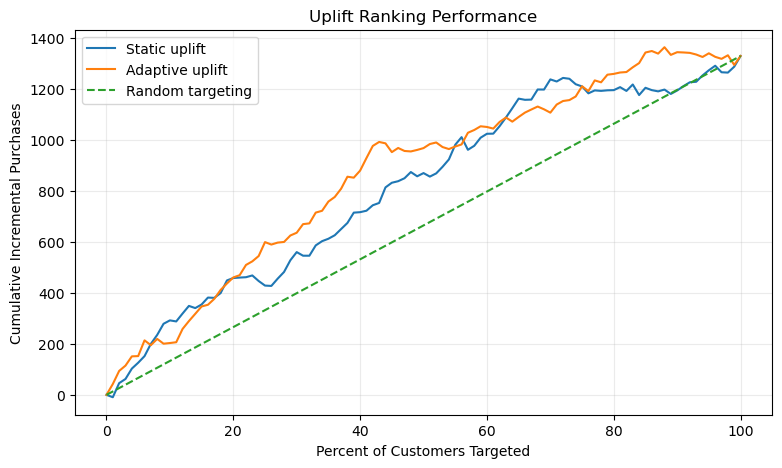

In [53]:
plt.figure(figsize=(9, 5))

plt.plot(
    static_gain["fraction_targeted"] * 100,
    static_gain["cumulative_gain"],
    label="Static uplift"
)

plt.plot(
    adaptive_gain["fraction_targeted"] * 100,
    adaptive_gain["cumulative_gain"],
    label="Adaptive uplift"
)

plt.plot(
    [0, 100],
    [0, total_random_gain],
    linestyle="--",
    label="Random targeting"
)

plt.xlabel("Percent of Customers Targeted")
plt.ylabel("Cumulative Incremental Purchases")
plt.title("Uplift Ranking Performance")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

In [54]:
instability_thresholds = train_data[
    "behavioral_instability_clean"
].quantile([0.25, 0.50, 0.75])

q25 = instability_thresholds.loc[0.25]
q50 = instability_thresholds.loc[0.50]
q75 = instability_thresholds.loc[0.75]

print(instability_thresholds)

0.25    0.285872
0.50    0.473181
0.75    0.770242
Name: behavioral_instability_clean, dtype: float64


In [55]:
def assign_instability_group(x):
    if x <= q25:
        return "Q1 Stable"
    elif x <= q50:
        return "Q2"
    elif x <= q75:
        return "Q3"
    else:
        return "Q4 High Change"


for df in [train_data, val_data, test_data]:
    df["instability_group_clean"] = (
        df["behavioral_instability_clean"]
        .apply(assign_instability_group)
    )

In [56]:
print(
    test_data["instability_group_clean"]
    .value_counts()
    .reindex([
        "Q1 Stable",
        "Q2",
        "Q3",
        "Q4 High Change"
    ])
)

instability_group_clean
Q1 Stable          9997
Q2                10124
Q3                 9830
Q4 High Change    10057
Name: count, dtype: int64


In [57]:
# STATIC S-LEARNER

test_static_treated = test_data[
    static_s_features
].copy()

test_static_control = test_data[
    static_s_features
].copy()

test_static_treated["treatment_flg"] = 1
test_static_control["treatment_flg"] = 0

test_static_pred_treated = (
    static_gb_s_model.predict_proba(
        test_static_treated
    )[:, 1]
)

test_static_pred_control = (
    static_gb_s_model.predict_proba(
        test_static_control
    )[:, 1]
)

test_static_uplift = (
    test_static_pred_treated
    - test_static_pred_control
)

In [58]:
# CLEAN ADAPTIVE S-LEARNER

test_adaptive_treated = test_data[
    adaptive_s_features_clean
].copy()

test_adaptive_control = test_data[
    adaptive_s_features_clean
].copy()

test_adaptive_treated["treatment_flg"] = 1
test_adaptive_control["treatment_flg"] = 0

test_adaptive_pred_treated = (
    adaptive_gb_s_model_clean.predict_proba(
        test_adaptive_treated
    )[:, 1]
)

test_adaptive_pred_control = (
    adaptive_gb_s_model_clean.predict_proba(
        test_adaptive_control
    )[:, 1]
)

test_adaptive_uplift = (
    test_adaptive_pred_treated
    - test_adaptive_pred_control
)

In [59]:
test_control_rate = test_data.loc[
    test_data["treatment_flg"] == 0,
    "target"
].mean()

test_treated_rate = test_data.loc[
    test_data["treatment_flg"] == 1,
    "target"
].mean()

test_ate = (
    test_treated_rate - test_control_rate
)

print(
    "Control:",
    round(test_control_rate, 4)
)

print(
    "Treated:",
    round(test_treated_rate, 4)
)

print(
    "ATE:",
    round(test_ate, 4)
)

Control: 0.6033
Treated: 0.6365
ATE: 0.0332


In [60]:
test_static_policy = evaluate_targeting_policy(
    test_data,
    test_static_uplift
)

test_adaptive_policy = evaluate_targeting_policy(
    test_data,
    test_adaptive_uplift
)

test_policy_comparison = (
    test_static_policy[
        ["budget", "ate", "incremental_per_10k"]
    ]
    .rename(columns={
        "ate": "static_ate",
        "incremental_per_10k":
            "static_per_10k"
    })
    .merge(
        test_adaptive_policy[
            ["budget", "ate", "incremental_per_10k"]
        ].rename(columns={
            "ate": "adaptive_ate",
            "incremental_per_10k":
                "adaptive_per_10k"
        }),
        on="budget"
    )
)

test_policy_comparison[
    "adaptive_minus_static"
] = (
    test_policy_comparison["adaptive_per_10k"]
    - test_policy_comparison["static_per_10k"]
)

test_policy_comparison.round(4)

,budget,static_ate,static_per_10k,adaptive_ate,adaptive_per_10k,adaptive_minus_static
0,0.1,0.0618,617.7174,0.0777,777.1396,159.4223
1,0.2,0.0533,533.1327,0.0583,582.9421,49.8093
2,0.3,0.0429,428.5134,0.0475,474.6746,46.1612
3,0.4,0.0420,420.1181,0.0410,409.6737,-10.4444
4,0.5,0.0406,406.3608,0.0418,417.9144,11.5536


In [61]:
test_static_gain = cumulative_gain_curve(
    test_data,
    test_static_uplift
)

test_adaptive_gain = cumulative_gain_curve(
    test_data,
    test_adaptive_uplift
)

test_static_auuc = np.trapezoid(
    test_static_gain["cumulative_gain"],
    test_static_gain["fraction_targeted"]
)

test_adaptive_auuc = np.trapezoid(
    test_adaptive_gain["cumulative_gain"],
    test_adaptive_gain["fraction_targeted"]
)

test_total_random_gain = (
    test_ate * len(test_data)
)

test_random_auuc = (
    test_total_random_gain / 2
)

test_static_qini = (
    test_static_auuc - test_random_auuc
)

test_adaptive_qini = (
    test_adaptive_auuc - test_random_auuc
)

print("Static AUUC:", round(test_static_auuc, 2))
print("Adaptive AUUC:", round(test_adaptive_auuc, 2))
print("Random AUUC:", round(test_random_auuc, 2))

print()

print("Static Qini:", round(test_static_qini, 2))
print("Adaptive Qini:", round(test_adaptive_qini, 2))

print(
    "Adaptive Qini improvement:",
    round(
        (
            test_adaptive_qini
            / test_static_qini - 1
        ) * 100,
        1
    ),
    "%"
)

Static AUUC: 796.25
Adaptive AUUC: 783.47
Random AUUC: 664.92

Static Qini: 131.33
Adaptive Qini: 118.55
Adaptive Qini improvement: -9.7 %


In [62]:
test_instability_eval = test_data[
    [
        "client_id",
        "treatment_flg",
        "target",
        "instability_group_clean"
    ]
].copy()

test_instability_eval[
    "static_uplift"
] = test_static_uplift

test_instability_eval[
    "adaptive_uplift"
] = test_adaptive_uplift


test_subgroup_results = []

group_order = [
    "Q1 Stable",
    "Q2",
    "Q3",
    "Q4 High Change"
]

for group in group_order:

    group_df = test_instability_eval[
        test_instability_eval[
            "instability_group_clean"
        ] == group
    ]

    static_result = subgroup_policy_effect(
        group_df,
        "static_uplift",
        budget=0.20
    )

    adaptive_result = subgroup_policy_effect(
        group_df,
        "adaptive_uplift",
        budget=0.20
    )

    test_subgroup_results.append({
        "instability_group": group,

        "static_n":
            static_result["n_targeted"],

        "static_per_10k":
            static_result[
                "incremental_per_10k"
            ],

        "adaptive_n":
            adaptive_result["n_targeted"],

        "adaptive_per_10k":
            adaptive_result[
                "incremental_per_10k"
            ]
    })


test_subgroup_results = pd.DataFrame(
    test_subgroup_results
)

test_subgroup_results[
    "adaptive_minus_static"
] = (
    test_subgroup_results[
        "adaptive_per_10k"
    ]
    -
    test_subgroup_results[
        "static_per_10k"
    ]
)

test_subgroup_results.round(2)

,instability_group,static_n,static_per_10k,adaptive_n,adaptive_per_10k,adaptive_minus_static
0,Q1 Stable,2014,675.83,2000,724.14,48.31
1,Q2,2025,617.46,2101,709.65,92.19
2,Q3,1966,203.42,1966,509.12,305.70
3,Q4 High Change,2012,643.56,2012,295.26,-348.30


In [63]:
test_bootstrap_results = []

for group in group_order:

    group_df = test_instability_eval[
        test_instability_eval[
            "instability_group_clean"
        ] == group
    ]

    result = bootstrap_policy_difference(
        group_df,
        budget=0.20,
        n_boot=2000,
        random_state=42
    )

    test_bootstrap_results.append({
        "instability_group": group,

        "difference_per_10k":
            result["mean_difference"] * 10000,

        "ci_lower_per_10k":
            result["ci_lower"] * 10000,

        "ci_upper_per_10k":
            result["ci_upper"] * 10000,

        "prob_adaptive_better":
            result["prob_adaptive_better"]
    })

test_bootstrap_results = pd.DataFrame(
    test_bootstrap_results
)

test_bootstrap_results.round(2)

,instability_group,difference_per_10k,ci_lower_per_10k,ci_upper_per_10k,prob_adaptive_better
0,Q1 Stable,85.26,-277.82,443.96,0.68
1,Q2,101.81,-276.77,475.06,0.69
2,Q3,282.58,-157.50,698.70,0.89
3,Q4 High Change,-346.59,-827.99,119.25,0.08


In [64]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [65]:
import torch
import torch.nn as nn

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

from sklearn.preprocessing import StandardScaler

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Apple Silicon support, otherwise CUDA/CPU
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1
Device: mps


In [69]:
print("train_data:", train_data.shape)
print("val_data:", val_data.shape)
print("test_data:", test_data.shape)
print("adaptive features:", len(adaptive_features_clean))

train_data: (120023, 66)
val_data: (40008, 66)
test_data: (40008, 66)
adaptive features: 41


In [70]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
torch.manual_seed(42)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.14.1
Device: mps


In [71]:
pytorch_features = list(adaptive_features_clean) + [
    "treatment_flg"
]

pytorch_scaler = StandardScaler()

X_train_nn = pytorch_scaler.fit_transform(
    train_data[pytorch_features]
)

X_val_nn = pytorch_scaler.transform(
    val_data[pytorch_features]
)

y_train_nn = train_data["target"].to_numpy()
y_val_nn = val_data["target"].to_numpy()

print("Train:", X_train_nn.shape)
print("Validation:", X_val_nn.shape)

Train: (120023, 42)
Validation: (40008, 42)


In [1]:
import time
import torch
import numpy as np

tiny = np.random.randn(1000, 42).astype(np.float32)

start = time.time()

tiny_tensor = torch.from_numpy(tiny)

print("Time:", time.time() - start)
print(tiny_tensor.shape)

Time: 0.0002503395080566406
torch.Size([1000, 42])


In [2]:
Time: 0.0002503395080566406
torch.Size([1000, 42])

torch.Size([1000, 42])

In [3]:
start = time.time()

X_train_tensor = torch.from_numpy(
    X_train_nn.astype(np.float32, copy=False)
)

print("Conversion time:", time.time() - start)
print(X_train_tensor.shape)

NameError: name 'X_train_nn' is not defined

In [ ]:
X_train_tensor = torch.tensor(
    X_train_nn,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_nn,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_nn,
    dtype=torch.float32
).reshape(-1, 1)

y_val_tensor = torch.tensor(
    y_val_nn,
    dtype=torch.float32
).reshape(-1, 1)

print("X train:", X_train_tensor.shape)
print("y train:", y_train_tensor.shape)
print("X val:", X_val_tensor.shape)
print("y val:", y_val_tensor.shape)

In [ ]:
class UpliftMLP(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


adaptive_nn = UpliftMLP(
    input_dim=42
).to(device)

print(adaptive_nn)

In [ ]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    adaptive_nn.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Ready to train.")